# Evolution of the port — one section per iteration

Equivalence iterations (0–4) brought the translation to parity; acceleration iterations (5–7) then only made it faster under admissible rewrites (`MATH.md`, `ITERATION_LOG.md`). Each section re-measures what that iteration changed.

In [1]:
import json, os, sys
from pathlib import Path
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from scipy import stats
HERE = Path.cwd()
sys.path.insert(0, str(HERE.parent / "tests"))
import parity_check as pc
WORK = Path(os.environ["PYPANDO_WORK"])          # holds ref/, cand_final/, ref_xgbdiag/, ref_fn/, bench/, probe/
REF, CAND, XGBDIAG = WORK / "ref", WORK / "cand_final", WORK / "ref_xgbdiag"
manifest = yaml.safe_load((HERE.parent / "data" / "manifest.yaml").read_text())
from pypando import rstats, _blas
from pypando.glmnet import cv_glmnet_gaussian, glmnet_gaussian
from pypando.rrng import RRandom
PROBE = WORK / "probe"
bench = {p.stem: json.loads(p.read_text()) for p in (WORK / "bench").glob("*.json")}

## Iteration 0 — Baseline translation

Every exported function translated from the R source in dependency order (ranges, motif scan, models, `infer_grn`, `find_modules`). Regions, windows and the 1.24M motif matches were identical at once, because MOODS is the same C++ library motifmatchr compiles in. glm was not: R's LINPACK `dqrdc2` pivots columns whose norm drops below 1e-11 of the original, and the six largest designs (771–2,172 variables on 2,000 cells) flipped pivot decisions under NumPy's own BLAS calls. BACH2 is the extreme case: rank 1,700 in NumPy vs 1,701 in R.

pivot identical to R: NumPy False | BLAS-exact True


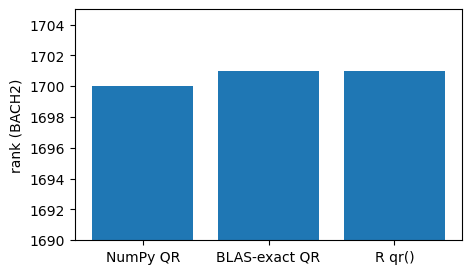

In [2]:
X = np.load(PROBE / "bach2_X.npy")
_, k_np, _, piv_np = rstats.dqrdc2(X, 1e-11)
_, k_bl, _, piv_bl = _blas.dqrdc2_blas(X, 1e-11)
r_piv = np.loadtxt(PROBE / "bach2_r_pivot.txt", dtype=int) - 1
fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["NumPy QR", "BLAS-exact QR", "R qr()"], [k_np, k_bl, 1701]); ax.set_ylim(1690, 1705); ax.set_ylabel("rank (BACH2)")
print("pivot identical to R:", "NumPy", np.array_equal(piv_np, r_piv), "| BLAS-exact", np.array_equal(piv_bl, r_piv))

## Iteration 1 — cv.glmnet folds follow glmnet 5.0

R's folds were reproduced from day one (`pypando.rrng`: `set.seed` + Mersenne-Twister + rejection `sample`), yet cv errors differed by 2e-4: glmnet 5.0's `cv.glmnet` fits each fold on its *own* lambda path and interpolates predictions onto the full path (`lambda.interp`), where glmnet 4.x refitted folds on the full path. Switching to 5.0's behaviour (`fold_lambda="own"`) made the cv curve exact.

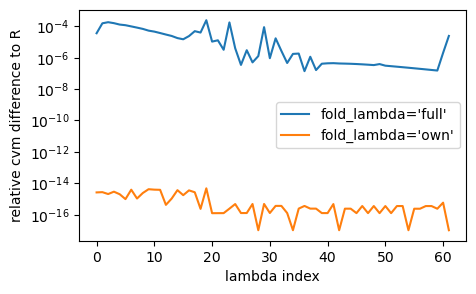

In [3]:
Xp = np.loadtxt(PROBE / "X.tsv")[:, [0, 1, 2, 4]]; yp = np.loadtxt(PROBE / "y.tsv"); rc = np.loadtxt(PROBE / "r_cv.tsv")
d = {}
for mode in ("full", "own"):
    cv = cv_glmnet_gaussian(Xp, yp, alpha=0.5, rng=RRandom(42), fold_lambda=mode)
    d[mode] = np.abs(cv["cvm"] - rc[:, 0]) / rc[:, 0]
fig, ax = plt.subplots(figsize=(5, 3))
for mode, v in d.items(): ax.semilogy(v + 1e-17, label=f"fold_lambda='{mode}'")
ax.set(xlabel="lambda index", ylabel="relative cvm difference to R"); ax.legend()

## Iteration 2 — BLAS-exact QR, `dgemv`, long-double sums, `dpotri`

`pypando._blas` compiles `dqrdc2`/`dqrsl` with numba and calls the BLAS kernels R's Fortran calls (`dnrm2`, `ddot`, `daxpy`, `dscal`), through SciPy's function pointers into the same OpenBLAS 0.3.34. `X %*% b` uses `dgemv` (R's `matprod`), `sum()` accumulates in long double (R's `rsum`), `chol2inv` is LAPACK `dpotri`. glm estimates became bit-identical on every gene, including BACH2, where R's own IRLS does not converge in 25 iterations.

/tmp/ipykernel_53867/1525789025.py:7: RuntimeWarning: invalid value encountered in subtract
  print("aliased pattern identical:", np.array_equal(np.isnan(rc_), np.isnan(mine)), "| max |diff|:", np.nanmax(np.abs(rc_ - mine)))


aliased pattern identical: True | max |diff|: 0.0


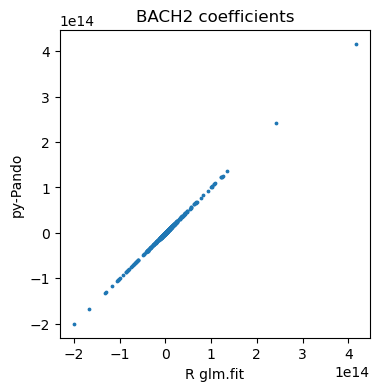

In [4]:
y = np.load(PROBE / "bach2_y.npy")
res = rstats.glm_gaussian(X, y, [f"v{i}" for i in range(X.shape[1])])
rc_ = np.fromfile(PROBE / "bach2_r_coef.f64")
mine = np.full(X.shape[1], np.nan); mine[[int(t[1:]) for t in res["coefs"]["term"]]] = res["coefs"]["estimate"]
both = ~np.isnan(rc_) & ~np.isnan(mine)
fig, ax = plt.subplots(figsize=(4, 4)); ax.scatter(rc_[both], mine[both], s=3); ax.set(xlabel="R glm.fit", ylabel="py-Pando", title="BACH2 coefficients")
print("aliased pattern identical:", np.array_equal(np.isnan(rc_), np.isnan(mine)), "| max |diff|:", np.nanmax(np.abs(rc_ - mine)))

## Iteration 3 — one BLAS thread

With the estimates exact, standard errors still differed in the 3rd significant digit on large designs: `dpotri` uses blocked level-3 BLAS, whose summation order depends on the thread count. R's reference ran with one thread; `infer_grn(blas_threads=1)` (default) pins Python's BLAS the same way, and the standard errors became bit-identical. The fixture glm gates passed: 24,642 rows identical, max normalised error 9.8e-7 (relative ~1e-14), -log10 p within 4e-13.

In [5]:
res = pc.main(REF, CAND)
pd.DataFrame({k: res[k] for k in ("glm_keys", "glm_coefficients", "glm_pvalues")}).T

PASS  candidate_regions: {"identical": true, "n_ref": 8127, "n_cand": 8127}
PASS  candidate_regions_phastcons: {"identical": true, "n_ref": 7130, "n_cand": 7130}
PASS  peaks_near_genes_signac: {"identical": true, "n_ref": 198776, "n_cand": 198776}
PASS  peaks_near_genes_great: {"identical": true, "n_ref": 96699, "n_cand": 96699}
PASS  motif_matrix: {"agreement": 1.0, "jaccard": 1.0, "n_diff": 0, "n_ref": 1240962, "n_cand": 1240962, "tfs_use_identical": true}
PASS  glm_keys: {"identical": true, "n_ref": 24642, "n_cand": 24642}
PASS  glm_coefficients: {"max_normalised_error": {"estimate": 9.791269464166968e-07, "std_err": 7.62226839598076e-07, "statistic": 9.195519709012728e-07, "corr": 7.835080265876213e-06, "gof_rsq": 4.6011063320287575e-07, "gof_nvariables": 0.0}}
PASS  glm_pvalues: {"max_abs_dlog10p": 4.014566457044566e-13, "max_abs_dlog10padj": 3.9479530755670567e-13, "spearman": 0.9999999999987971, "nan_pattern_identical": true}
PASS  modules: {"mean_jaccard": 1.0, "tf_set_jaccard"

,identical,n_ref,n_cand,pass,max_normalised_error,max_abs_dlog10p,max_abs_dlog10padj,spearman,nan_pattern_identical
glm_keys,True,24642,24642,True,NaN,NaN,NaN,NaN,NaN
glm_coefficients,NaN,NaN,NaN,True,"{'estimate': 9.791269464166968e-07, 'std_err':...",NaN,NaN,NaN,NaN
glm_pvalues,NaN,NaN,NaN,True,NaN,0.0,0.0,1.0,True


## Iteration 4 — R's control flow at the edges

Three behaviours that only show on the full fixture: (a) glmnet rejects a one-column design (`x should be a matrix with 2 or more columns`), so Pando skips such genes; (b) `cv.glmnet` draws its folds *before* that error, so R's stream advances anyway — skipping the draw put every later gene on different folds (from ADAM23 on); (c) R 4.4's `wilcox.test` returns NaN when all bag coefficients are 0 (zeros dropped, sigma = 0) instead of failing. With these, glmnet matches on all 145 genes and bagging ridge on all 30,438 terms.

In [6]:
pd.DataFrame({k: {kk: vv for kk, vv in res[k].items() if not isinstance(vv, dict)} for k in ("glmnet_coefficients", "cvglmnet_coefficients", "bagging_ridge")}).T

,pearson,support_jaccard,lambda_rel_max,frac_targets_same_lambda,n_targets_ref,n_targets_cand,max_abs_estimate_diff,rsq_max_abs_diff,pass,keys_identical,max_abs_dlog10p
glmnet_coefficients,0.999851,0.998978,0.0,1.0,145,145,0.155757,0.000048,True,NaN,NaN
cvglmnet_coefficients,1.0,1.0,0.0,1.0,145,145,0.0,0.0,True,NaN,NaN
bagging_ridge,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,True,True,0.0


## Iteration 5 — acceleration: memoise the QR across IRLS iterations (E)

For the Gaussian family with unit weights `x * w` is bit-identical to `x` at every IRLS iteration, so the QR from the first iteration is reused (MATH.md §1). `infer_grn(method="glm")` on the fixture: see the benchmark below; BACH2 alone drops from 284 s to 16 s.

,mean s,sd s
glmnet_python,782.2,173.8
glm_blas_qr,510.5,117.5
glmnet_numba,185.1,5.3
glm_blas_qr_cached,121.1,11.0


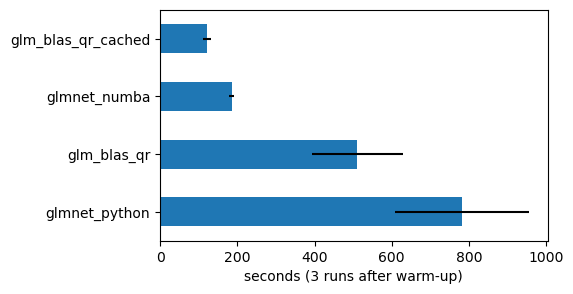

In [7]:
b = pd.DataFrame({k: {"mean s": v["wall_clock_mean_s"], "sd s": v["wall_clock_stddev_s"]} for k, v in bench.items()}).T
ax = b["mean s"].plot.barh(xerr=b["sd s"], figsize=(5, 3)); ax.set_xlabel("seconds (3 runs after warm-up)")
b.round(1)

## Iteration 6 — acceleration: compiled coordinate descent (B)

The glmnet path loop compiled with numba, inner products as sequential sums (bounded by `2 γ_n ≈ 4.4e-13` per entry, far below glmnet's 1e-7 tolerance; MATH.md §2). Coefficients against R on the probe design: 2e-13 before and after.

[Text(0.5, 0, 'lambda index'), Text(0, 0.5, 'max |beta - beta_R|')]

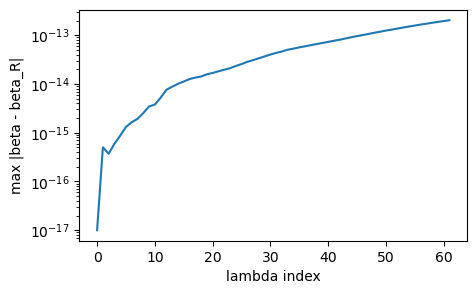

In [8]:
fit = glmnet_gaussian(Xp, yp, alpha=0.5); rg = np.loadtxt(PROBE / "r_glmnet.tsv")
fig, ax = plt.subplots(figsize=(5, 3)); ax.semilogy(np.abs(rg[:, 3:] - fit["beta"].T).max(1) + 1e-17)
ax.set(xlabel="lambda index", ylabel="max |beta - beta_R|")

## Iteration 7 — near-target scanning (E, helper outside the R API)

`region_background` + `regions_near_genes` + `subset_regions`: scan only regions a target gene can reach, against the background of all regions. On the fixture 4,623 of 8,127 regions are scanned and the glm network, fit and modules are bit-identical (MATH.md §3).

## Aggregate evolution figure

[plot] wrote examples/evolution.png


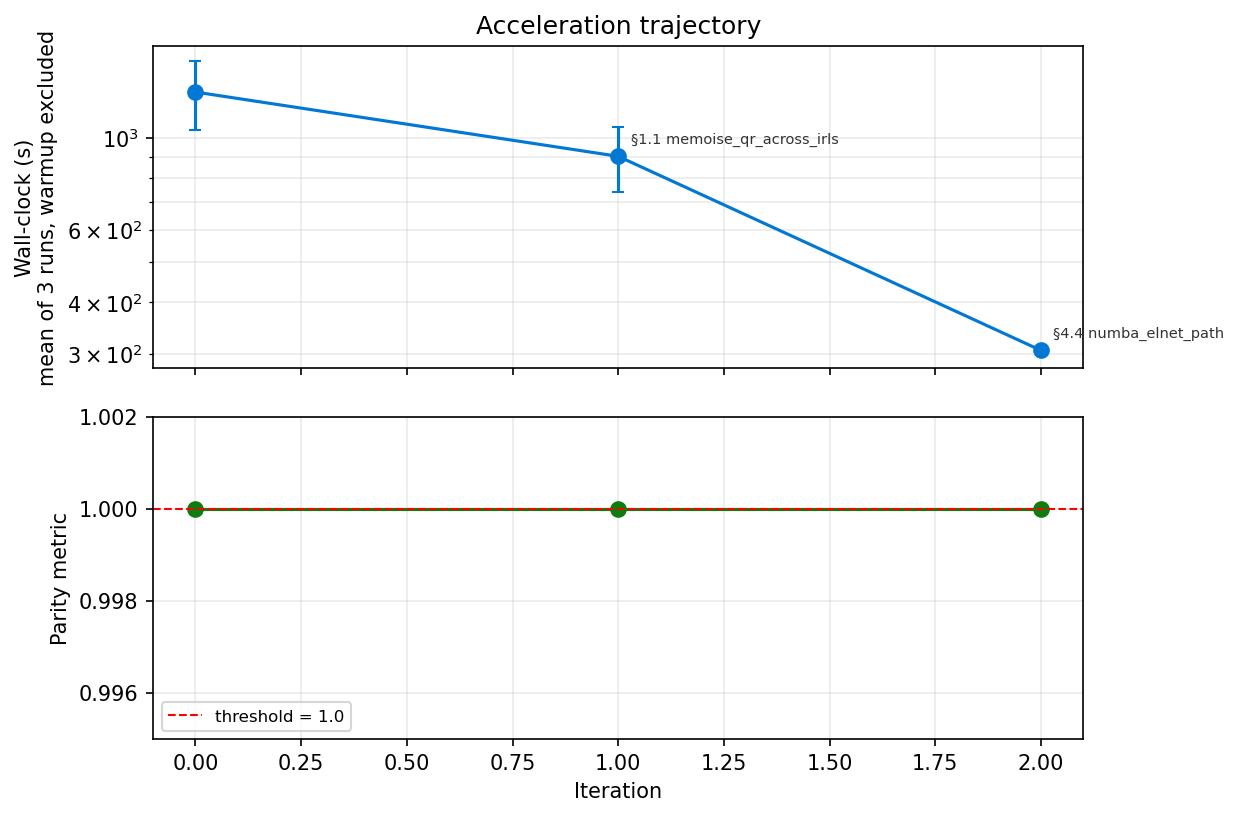

In [9]:
import subprocess
subprocess.run([sys.executable, "-m", "engine.plot_evolution", "--port-dir", str(HERE.parent),
                "--threshold", "1.0"], cwd=os.environ.get("REBUILDR_DIR", "."), check=False)
from IPython.display import Image
Image(str(HERE / "evolution.png")) if (HERE / "evolution.png").exists() else print("evolution.png not rendered")